# Bank Customer Churn Analysis


This notebook studies which customers leave the bank, why they leave, and where the financial risk is concentrated. The goal is to turn the raw customer table into a clear story: overall churn, the main drivers (products, age, country, activity, reasons), and a shortlist of remaining customers to protect.


## 1. Setup and data overview

Load the churn dataset and inspect its structure before any analysis. We check row count, column types, missing values, and how many unique values each field has, so later charts are based on a clean, understood table.


In [6]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import numpy as  np
import matplotlib.pyplot as plt

# Part 1 palette: lighter blue and red
NAVY = "#5B9BD5"
TEAL = "#8EC4E6"
CORAL = "#E89292"
GOLD = "#E0A35A"
SLATE = "#9B7BAF"
MIST = "#B8D4EA"
INK = "#243040"

# Part 2 palette: fixed color per churn reason (from the reason pie)
REASON_ORDER = [
    "Better Rates or Competitor Offer",
    "Relocation / Personal Circumstances",
    "Poor Customer Service Experience",
    "Switched to Digital / Mobile Bank",
    "High Account & Maintenance Fees",
]
REASON_COLORS = {
    "Better Rates or Competitor Offer": "#3A6D7C",
    "Relocation / Personal Circumstances": "#9B7BAF",
    "Poor Customer Service Experience": "#D4A5A8",
    "Switched to Digital / Mobile Bank": "#8BA889",
    "High Account & Maintenance Fees": "#E0A35A",
}
AGE_PALETTE = ["#4F8FCB", "#6BA8D8", "#8BBDE4", "#A8D0EE", "#C9E4F6", "#E3F2FA"]

plt.rcParams.update({
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.titlecolor": INK,
    "axes.labelcolor": INK,
    "text.color": INK,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
})


def reason_palette(columns):
    return [REASON_COLORS.get(col, MIST) for col in columns]


def ordered_reasons(frame):
    cols = [c for c in REASON_ORDER if c in frame.columns]
    cols += [c for c in frame.columns if c not in cols]
    return frame[cols]


In [8]:
db_bank_churn = pd.read_csv("../data/Bank_Churn_Data.csv")

In [9]:
db_bank_churn


,O,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited,Tenure,Account_Open_Date,Exit_Date,Churn_Reason,Customer_Segment
0,1,619,France,Female,42,101348.88,0.00,1,1,1,1,2,2021-04-13,2023-09-28,Poor Customer Service Experience,Lost / Churned
1,2,608,Spain,Female,41,112542.58,83807.86,1,1,1,0,1,2022-04-17,NaN,Retained,Standard Retained
2,3,502,France,Female,42,113931.57,159660.80,3,0,0,1,8,2015-03-13,2023-04-13,High Account & Maintenance Fees,VIP Lost
3,4,699,France,Female,39,93826.63,0.00,2,0,0,0,1,2022-05-02,NaN,Retained,Standard Retained
4,5,850,Spain,Female,43,79084.10,125510.82,1,1,1,0,2,2021-08-03,NaN,Retained,VIP Stable
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,771,France,Male,39,96270.64,0.00,2,0,0,0,5,2018-06-23,NaN,Retained,Standard Retained
9996,9997,516,France,Male,35,101699.77,57369.61,1,1,1,0,10,2013-02-27,NaN,Retained,Standard Retained
9997,9998,709,France,Female,36,42085.58,0.00,1,1,1,1,7,2016-07-17,2023-09-09,Relocation / Personal Circumstances,Lost / Churned
9998,9999,772,Germany,Male,42,92888.52,75075.31,2,0,0,1,3,2020-05-10,2023-02-21,Relocation / Personal Circumstances,Lost / Churned


In [10]:
db_bank_churn.shape

(10000, 16)

In [11]:
db_bank_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   O                  10000 non-null  int64  
 1   CreditScore        10000 non-null  int64  
 2   Geography          10000 non-null  str    
 3   Gender             10000 non-null  str    
 4   Age                10000 non-null  int64  
 5   EstimatedSalary    10000 non-null  float64
 6   Balance            10000 non-null  float64
 7   NumOfProducts      10000 non-null  int64  
 8   HasCrCard          10000 non-null  int64  
 9   IsActiveMember     10000 non-null  int64  
 10  Exited             10000 non-null  int64  
 11  Tenure             10000 non-null  int64  
 12  Account_Open_Date  10000 non-null  str    
 13  Exit_Date          2037 non-null   str    
 14  Churn_Reason       10000 non-null  str    
 15  Customer_Segment   10000 non-null  str    
dtypes: float64(2), int64(8), str(6)
me

In [12]:
db_bank_churn.isnull().sum()

O                       0
CreditScore             0
Geography               0
Gender                  0
Age                     0
EstimatedSalary         0
Balance                 0
NumOfProducts           0
HasCrCard               0
IsActiveMember          0
Exited                  0
Tenure                  0
Account_Open_Date       0
Exit_Date            7963
Churn_Reason            0
Customer_Segment        0
dtype: int64

In [13]:
db_bank_churn.nunique()

O                    10000
CreditScore            460
Geography                3
Gender                   2
Age                     70
EstimatedSalary       9999
Balance               6382
NumOfProducts            4
HasCrCard                2
IsActiveMember           2
Exited                   2
Tenure                  11
Account_Open_Date     3574
Exit_Date              364
Churn_Reason             6
Customer_Segment         5
dtype: int64

## 2. Business snapshot

Measure the headline numbers first: how many customers there are, how many left, the churn rate, the balance that left, and the assumed 4% profit loss on that balance. We also take a first look at churn by quarter, reason, country, and age, to see where the story might be strongest.


In [14]:
# Total customers
total_customers = len(db_bank_churn)
print(f"Total customers: {total_customers}")

# How many churned
churned_customers = db_bank_churn['Exited'].sum()
print(f"Customers who churned: {churned_customers}")

# Churn rate
churn_rate = churned_customers / total_customers * 100
print(f"Churn rate: {churn_rate:.2f}%")

# Lost checking-account balance — total balance that left
churned_balance_loss = db_bank_churn.loc[db_bank_churn['Exited'] == 1, 'Balance'].sum()
print(f"Lost balance: {churned_balance_loss:,.2f}")

# Lost profit — total departed balance * 0.04
profit_loss = churned_balance_loss * 0.04
print(f"Lost profit (assuming 4% of every departed balance): {profit_loss:,.2f}")

# ---- Churn share by quarter, out of all churned customers ----
db_bank_churn['Exit_Date'] = pd.to_datetime(db_bank_churn['Exit_Date'], errors='coerce')
db_bank_churn['Exit_Quarter'] = db_bank_churn['Exit_Date'].dt.to_period('Q')

# How many churned in each quarter, out of all churned customers
churned_quarters = db_bank_churn.loc[db_bank_churn["Exited"] == 1, 'Exit_Quarter']
quarterly_churn_counts = churned_quarters.value_counts().sort_index()
quarterly_churn_pct = (quarterly_churn_counts / churned_customers) * 100

print("Churn share by quarter, out of all churned customers (%):")
print(quarterly_churn_pct)

# Churn-reason mix
churn_reason_dist = db_bank_churn.loc[db_bank_churn['Exited'] == 1, 'Churn_Reason'].value_counts(normalize=True) * 100
print("Churn mix by reason (%):")
print(churn_reason_dist)

# Churn rate by country
country_churn_rate = db_bank_churn.groupby('Geography')['Exited'].mean() * 100
print("Churn rate by country (%):")
print(country_churn_rate)

# ---- Churn rate by age range ----
age_bins = [17, 30, 40, 50, 60, np.inf]
age_labels = ['18-30', '31-40', '41-50', '51-60', '61+']
db_bank_churn['Age_Group'] = pd.cut(db_bank_churn['Age'], bins=age_bins, labels=age_labels, right=True, include_lowest=True)

age_group_churn_rate = db_bank_churn.groupby('Age_Group')['Exited'].mean() * 100
print("Churn rate by age range (age range -> churn rate):")
for age_group, rate in age_group_churn_rate.items():
    print(f"{age_group}: {rate:.6f}")


Total customers: 10000
Customers who churned: 2037
Churn rate: 20.37%
Lost balance: 185,588,094.63
Lost profit (assuming 4% of every departed balance): 7,423,523.79
Churn share by quarter, out of all churned customers (%):
Exit_Quarter
2023Q1    23.073147
2023Q2    23.564065
2023Q3    25.429553
2023Q4    27.933235
Freq: Q-DEC, Name: count, dtype: float64
Churn mix by reason (%):
Churn_Reason
Better Rates or Competitor Offer       27.000491
Relocation / Personal Circumstances    21.256750
Poor Customer Service Experience       17.525773
Switched to Digital / Mobile Bank      17.525773
High Account & Maintenance Fees        16.691213
Name: proportion, dtype: float64
Churn rate by country (%):
Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64
Churn rate by age range (age range -> churn rate):
18-30: 7.520325
31-40: 12.087171
41-50: 33.965517
51-60: 56.210790
61+: 24.784483


## 3. Churn over time

Plot how many customers left in each quarter and how much balance left with them. We are looking for whether churn is stable or accelerating, and whether later quarters also carry a larger financial loss.


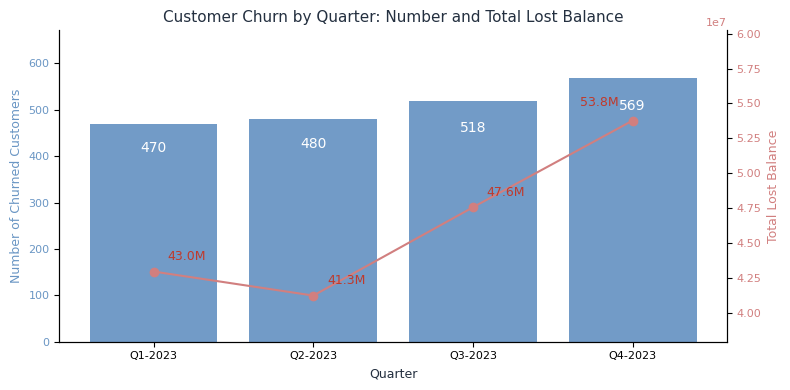

In [15]:
# Plotting customer churn over the year by quarters, including total balance that left per quarter

import matplotlib.pyplot as plt

# Group by quarter: number of customers who left in each quarter
quarterly_churn_counts = db_bank_churn.loc[db_bank_churn['Exited'] == 1].groupby('Exit_Quarter').size().sort_index()

# Group by quarter: total balance lost in each quarter
quarterly_churned_balance = db_bank_churn.loc[db_bank_churn['Exited'] == 1].groupby('Exit_Quarter')['Balance'].sum().sort_index()

# Make quarter names more readable, e.g., '2022Q3' -> 'Q3-2022'
def nice_quarter_label(quarter_period):
    if hasattr(quarter_period, 'year') and hasattr(quarter_period, 'quarter'):
        return f"Q{quarter_period.quarter}-{quarter_period.year}"
    q_str = str(quarter_period)
    if 'Q' in q_str:
        year, qpart = q_str.split('Q')
        return f"Q{qpart}-{year}"
    return str(quarter_period)

quarter_labels = [nice_quarter_label(idx) for idx in quarterly_churn_counts.index]

fig, ax1 = plt.subplots(figsize=(8, 4))
bar_color = "#6A96C4"
line_color = "#D17F7F"

ax1.set_xlabel('Quarter')
ax1.set_ylabel('Number of Churned Customers', color=bar_color)
bars1 = ax1.bar(quarter_labels, quarterly_churn_counts.values, color=bar_color, alpha=0.95, label='Churned Customers')
ax1.tick_params(axis='y', labelcolor=bar_color)
ax1.set_ylim(0, quarterly_churn_counts.max() * 1.18)

for rect in bars1:
    height = rect.get_height()
    ax1.annotate(f'{int(height)}',
                 xy=(rect.get_x() + rect.get_width() / 2, height * 0.92),
                 ha='center', va='top', color='white', fontsize=10)

ax2 = ax1.twinx()
ax2.spines['top'].set_visible(False)
ax2.set_ylabel('Total Lost Balance', color=line_color)
quarter_labels_balance = [nice_quarter_label(idx) for idx in quarterly_churned_balance.index]
ax2.plot(quarter_labels_balance, quarterly_churned_balance.values, color=line_color, marker='o', label='Total Lost Balance')
ax2.tick_params(axis='y', labelcolor=line_color)
y_min, y_max = quarterly_churned_balance.min(), quarterly_churned_balance.max()
ax2.set_ylim(y_min * 0.92, y_max * 1.12)

n_pts = len(quarter_labels_balance)
for i, (x, y) in enumerate(zip(quarter_labels_balance, quarterly_churned_balance.values)):
    is_last = i == n_pts - 1
    ax2.annotate(
        f'{y/1e6:.1f}M',
        xy=(x, y),
        xytext=(-10, 8) if is_last else (10, 6),
        textcoords="offset points",
        ha='right' if is_last else 'left',
        va='bottom',
        color='#C0392B',
        fontsize=9
    )

plt.title("Customer Churn by Quarter: Number and Total Lost Balance")
fig.tight_layout()
plt.show()


## 4. Products and churn

Compare churn rate, total customers, and number of churned customers by how many products each person holds. We are looking for product counts that are unusually risky (or unusually safe), not just large groups.


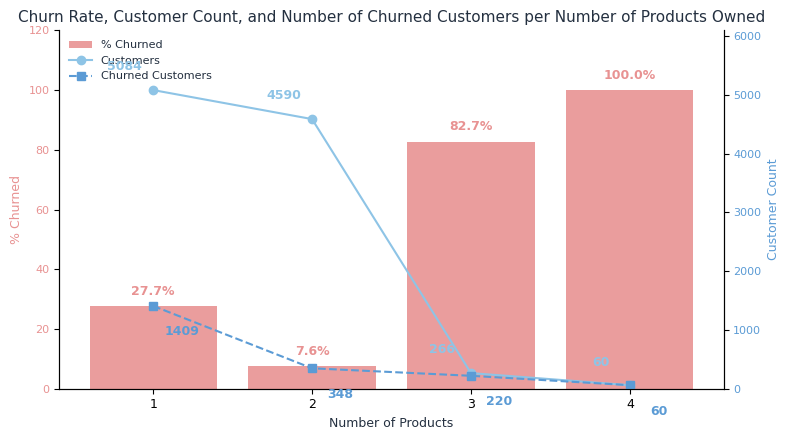

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Add 'is_churned' column
db_bank_churn['is_churned'] = (db_bank_churn['Exited'] == 1).astype(int)

# Group by number of products
prod_group = db_bank_churn.groupby('NumOfProducts')
num_customers_per_group = prod_group.size()
num_churned_per_group = prod_group['is_churned'].sum()
churn_pct_per_group = (num_churned_per_group / num_customers_per_group) * 100

fig, ax1 = plt.subplots(figsize=(8, 4.5))

bars1 = ax1.bar(num_customers_per_group.index.astype(str), churn_pct_per_group, color=CORAL, alpha=0.9, label='% Churned')
ax1.set_xlabel('Number of Products')
ax1.set_ylabel('% Churned', color=CORAL)
ax1.tick_params(axis='y', labelcolor=CORAL)
ax1.set_ylim(0, max(10, churn_pct_per_group.max()*1.2))

for rect in bars1:
    height = rect.get_height()
    ax1.annotate(f'{height:.1f}%',
                 xy=(rect.get_x() + rect.get_width()/2, height),
                 xytext=(0, 6), textcoords="offset points",
                 ha='center', va='bottom', color=CORAL, fontsize=9, fontweight='bold')

ax2 = ax1.twinx()
ax2.spines['top'].set_visible(False)

line2 = ax2.plot(num_customers_per_group.index.astype(str), num_customers_per_group, color=TEAL, marker='o', linestyle='-', label='Customers')
line3 = ax2.plot(num_churned_per_group.index.astype(str), num_churned_per_group, color=NAVY, marker='s', linestyle='--', label='Churned Customers')

ax2.set_ylabel('Customer Count', color=NAVY)
ax2.tick_params(axis='y', labelcolor=NAVY)
ax2.set_ylim(0, max(num_customers_per_group.max(), num_churned_per_group.max()) * 1.2)

offset = 0.18
bar_positions = np.arange(len(num_customers_per_group.index.astype(str)))

for i, (x, y) in enumerate(zip(bar_positions, num_customers_per_group)):
    ax2.annotate(f'{int(y)}',
                 xy=(x - offset, y),
                 xytext=(0, 12), textcoords='offset points',
                 ha='center', va='bottom', color=TEAL, fontsize=9, fontweight='bold')

for i, (x, y) in enumerate(zip(bar_positions, num_churned_per_group)):
    ax2.annotate(f'{int(y)}',
                 xy=(x + offset, y),
                 xytext=(0, -14), textcoords='offset points',
                 ha='center', va='top', color=NAVY, fontsize=9, fontweight='bold')

ax1.set_xticks(bar_positions)
ax1.set_xticklabels(num_customers_per_group.index.astype(str), fontsize=9)

lines_labels = [bars1] + line2 + line3
labels = ['% Churned', 'Customers', 'Churned Customers']
ax1.legend(lines_labels, labels, loc='upper left', fontsize=8, frameon=False)

plt.title("Churn Rate, Customer Count, and Number of Churned Customers per Number of Products Owned")
fig.tight_layout()
plt.show()


## 5. Age and churn

Split customers into age ranges and show churn rate together with headcount. We are looking for the ages where leaving is most common, and whether those groups are large enough to matter.


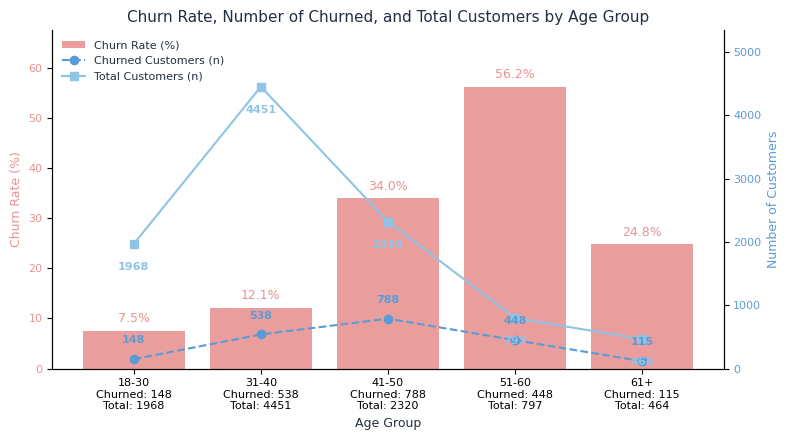

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define age bins and labels
age_bins = [18, 31, 41, 51, 61, np.inf]
age_labels = ['18-30', '31-40', '41-50', '51-60', '61+']
db_bank_churn['Age_Range'] = pd.cut(db_bank_churn['Age'], bins=age_bins, labels=age_labels, right=False, include_lowest=True)

churns_per_age_group = db_bank_churn[db_bank_churn['is_churned'] == 1].groupby('Age_Range').size().reindex(age_labels, fill_value=0)
customers_per_age_group = db_bank_churn.groupby('Age_Range').size().reindex(age_labels, fill_value=0)
churn_rate_per_age_group = (churns_per_age_group / customers_per_age_group) * 100

fig, ax1 = plt.subplots(figsize=(8, 4.5))

bars = ax1.bar(age_labels, churn_rate_per_age_group, color=CORAL, alpha=0.9, label='Churn Rate (%)')
ax1.set_xlabel('Age Group')
ax1.set_ylabel('Churn Rate (%)', color=CORAL)
ax1.tick_params(axis='y', labelcolor=CORAL)
ax1.set_ylim(0, max(10, churn_rate_per_age_group.max()*1.2))

for rect in bars:
    height = rect.get_height()
    ax1.annotate(f'{height:.1f}%',
                 xy=(rect.get_x() + rect.get_width() / 2, height),
                 xytext=(0, 4), textcoords="offset points",
                 ha='center', va='bottom', color=CORAL, fontsize=9)

ax2 = ax1.twinx()
ax2.spines['top'].set_visible(False)

points_churned = ax2.plot(
    age_labels, churns_per_age_group,
    color=NAVY, marker='o', linestyle='--', label='Churned Customers (n)'
)
points_total = ax2.plot(
    age_labels, customers_per_age_group,
    color=TEAL, marker='s', linestyle='-', label='Total Customers (n)'
)

ax2.set_ylabel('Number of Customers', color=NAVY)
ax2.tick_params(axis='y', labelcolor=NAVY)
ax2.set_ylim(0, max(customers_per_age_group.max(), churns_per_age_group.max()) * 1.2)

xticks_labels = [
    f"{label}\nChurned: {churns_per_age_group[label]}\nTotal: {customers_per_age_group[label]}"
    for label in age_labels
]
ax1.set_xticks(range(len(age_labels)))
ax1.set_xticklabels(xticks_labels, fontsize=8)

for i, (label, x) in enumerate(zip(age_labels, range(len(age_labels)))):
    ax2.annotate(f'{churns_per_age_group[label]}',
                 xy=(x, churns_per_age_group[label]),
                 xytext=(0, 10), textcoords='offset points',
                 fontsize=8, color=NAVY,
                 ha='center', va='bottom', fontweight='bold')
    ax2.annotate(f'{customers_per_age_group[label]}',
                 xy=(x, customers_per_age_group[label]),
                 xytext=(0, -13), textcoords='offset points',
                 fontsize=8, color=TEAL,
                 ha='center', va='top', fontweight='bold')

lines_labels = [bars] + points_churned + points_total
labels = ['Churn Rate (%)', 'Churned Customers (n)', 'Total Customers (n)']
ax1.legend(lines_labels, labels, loc='upper left', fontsize=8, frameon=False)

plt.title("Churn Rate, Number of Churned, and Total Customers by Age Group")
fig.tight_layout()
plt.show()


## 6. Financial loss by age

Translate churn into money: estimated loss per age group as 4% of the departed balance. We are looking for which ages destroy the most value, which may differ from the ages with the highest churn *rate*.


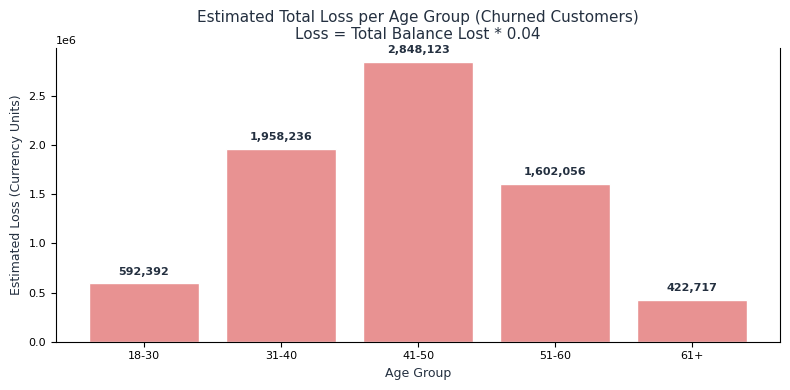

In [18]:
import matplotlib.pyplot as plt

# Calculate 'loss' per age group as SUM(Balance) * 0.04 for churned customers
age_group_col = "Age_Group" if "Age_Group" in db_bank_churn.columns else "age_group"
if age_group_col not in db_bank_churn.columns:
    age_bins = [18, 25, 35, 45, 55, 65, 100]
    age_labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']
    db_bank_churn['Age_Group'] = pd.cut(db_bank_churn['Age'], bins=age_bins, labels=age_labels, right=False)
    age_group_col = 'Age_Group'

loss_by_age = db_bank_churn[db_bank_churn['Exited'] == 1].groupby(age_group_col)['Balance'].sum() * 0.04

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(loss_by_age.index.astype(str), loss_by_age.values, color=CORAL, edgecolor='white')
ax.set_title("Estimated Total Loss per Age Group (Churned Customers)\nLoss = Total Balance Lost * 0.04")
ax.set_xlabel("Age Group")
ax.set_ylabel("Estimated Loss (Currency Units)")
ax.set_xticks(range(len(loss_by_age)))
ax.set_xticklabels(loss_by_age.index.astype(str), rotation=0)
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:,.0f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=8, fontweight='bold', color=INK)
fig.tight_layout()
plt.show()


## 7. Geography, age, and loss

Stack churned customers by country and age, and label the estimated loss on each segment. We are looking for country–age combinations that combine high volume with high financial impact.


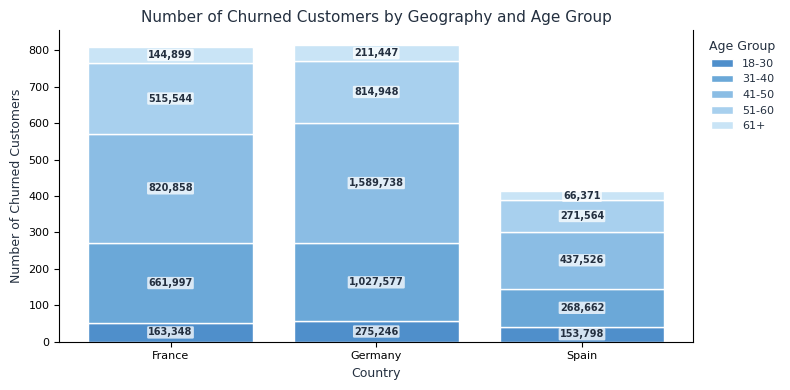

In [19]:
import matplotlib.pyplot as plt

# Make sure the Age_Group column exists (as in the previous cell)
age_group_col = "Age_Group" if "Age_Group" in db_bank_churn.columns else "age_group"
if age_group_col not in db_bank_churn.columns:
    age_bins = [18, 25, 35, 45, 55, 65, 100]
    age_labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']
    db_bank_churn['Age_Group'] = pd.cut(db_bank_churn['Age'], bins=age_bins, labels=age_labels, right=False)
    age_group_col = 'Age_Group'

churned = db_bank_churn[db_bank_churn['Exited'] == 1]
count_by_geo_age = churned.groupby(['Geography', age_group_col]).size().unstack(fill_value=0)
sum_balance_by_geo_age = churned.groupby(['Geography', age_group_col])['Balance'].sum().unstack(fill_value=0) * 0.04

fig, ax = plt.subplots(figsize=(8, 4))
age_groups = list(count_by_geo_age.columns)
bottom = None
for idx, age_group in enumerate(age_groups):
    values = count_by_geo_age[age_group]
    color = AGE_PALETTE[idx % len(AGE_PALETTE)]
    ax.bar(count_by_geo_age.index, values, bottom=bottom, label=str(age_group), color=color, edgecolor='white')
    bottom = values if bottom is None else bottom + values

ax.set_xlabel('Country')
ax.set_ylabel('Number of Churned Customers')
ax.set_title('Number of Churned Customers by Geography and Age Group')
ax.legend(title='Age Group', fontsize=8, title_fontsize=9, bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
plt.tight_layout()

n_countries = count_by_geo_age.shape[0]
n_age_groups = count_by_geo_age.shape[1]
countries = list(count_by_geo_age.index)
age_group_labels = list(count_by_geo_age.columns)
patches = ax.patches

for i, p in enumerate(patches):
    col = i // n_countries
    row = i % n_countries
    if col < n_age_groups and row < n_countries:
        country = countries[row]
        age_group = age_group_labels[col]
        value = sum_balance_by_geo_age.loc[country, age_group]
        if p.get_height() > 0 and value > 0:
            ax.annotate(
                f'{value:,.0f}',
                (p.get_x() + p.get_width()/2, p.get_y() + p.get_height()/2),
                ha='center', va='center', fontsize=7,
                color=INK, fontweight='bold', rotation=0,
                bbox=dict(boxstyle="round,pad=0.12", fc="white", alpha=0.75, edgecolor='none')
            )

plt.show()


## 8. Why customers leave

The next charts move from *who* leaves to *why*. We start with the overall mix of churn reasons, then split that mix by products, age, country, and activity, to see whether the same reasons show up everywhere or only in specific groups.


### 8.1 Overall reason mix

Show the share of each churn reason among customers who already left. We are looking for the dominant reasons at bank level before drilling into segments.


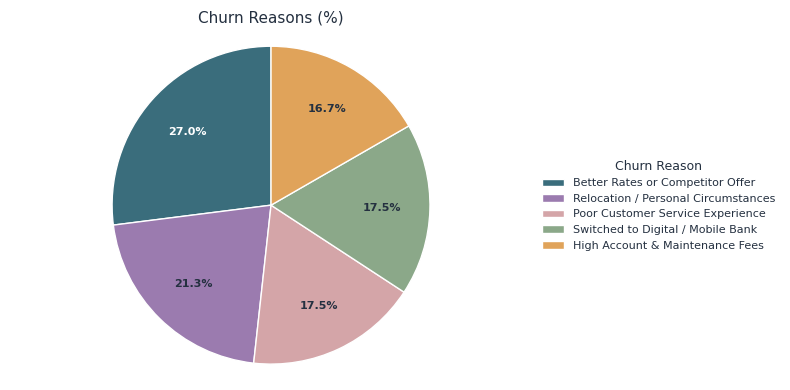

In [20]:
import matplotlib.pyplot as plt

churn_reasons = (
    db_bank_churn.loc[db_bank_churn['Exited'] == 1, 'Churn_Reason']
    .value_counts()
    .reindex([c for c in REASON_ORDER if c in db_bank_churn['Churn_Reason'].unique()])
)

fig, ax = plt.subplots(figsize=(8, 4))
colors = reason_palette(churn_reasons.index)

wedges, texts, autotexts = ax.pie(
    churn_reasons,
    labels=None,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.7,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1}
)

for t, name in zip(autotexts, churn_reasons.index):
    t.set_fontsize(8)
    t.set_fontweight('bold')
    t.set_color('white' if name == 'Better Rates or Competitor Offer' else INK)

ax.set_title('Churn Reasons (%)')
ax.legend(
    wedges,
    churn_reasons.index,
    title='Churn Reason',
    loc='center left',
    bbox_to_anchor=(1.0, 0.5),
    fontsize=8,
    title_fontsize=9,
    frameon=False
)
ax.axis('equal')
plt.tight_layout()
plt.show()


### 8.2 Reasons by number of products

For each product-count group, show how many people left and what share each reason takes. We are looking for whether one-product customers leave for different reasons than multi-product customers.


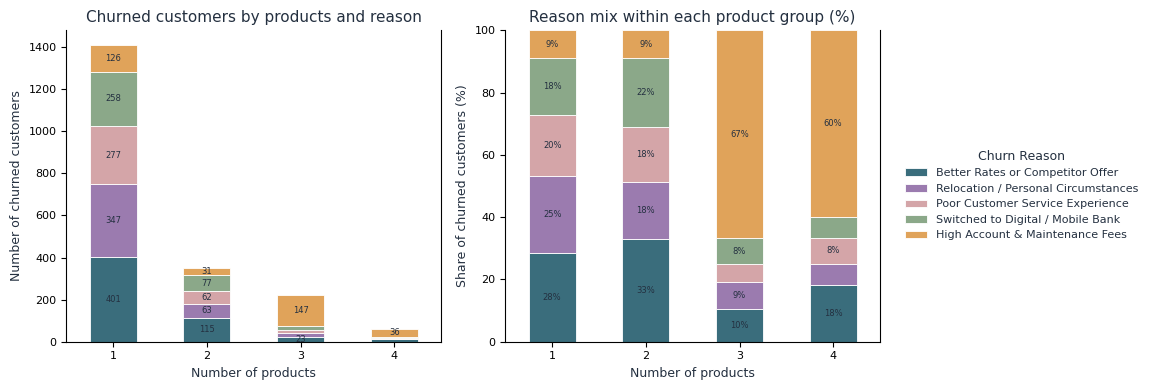

Churn_Reason   Better Rates or Competitor Offer  \
NumOfProducts                                     
1                                           401   
2                                           115   
3                                            23   
4                                            11   

Churn_Reason   Relocation / Personal Circumstances  \
NumOfProducts                                        
1                                              347   
2                                               63   
3                                               19   
4                                                4   

Churn_Reason   Poor Customer Service Experience  \
NumOfProducts                                     
1                                           277   
2                                            62   
3                                            13   
4                                             5   

Churn_Reason   Switched to Digital / Mobile Bank  \
NumOfProd

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

churned = db_bank_churn.loc[db_bank_churn['Exited'] == 1]
counts = ordered_reasons(
    pd.crosstab(churned['NumOfProducts'], churned['Churn_Reason']).sort_index()
)
pct = counts.div(counts.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
colors = reason_palette(counts.columns)

counts.plot(
    kind='bar', stacked=True, ax=axes[0], color=colors,
    edgecolor='white', linewidth=0.6, legend=False
)
axes[0].set_title('Churned customers by products and reason')
axes[0].set_xlabel('Number of products')
axes[0].set_ylabel('Number of churned customers')
axes[0].tick_params(axis='x', rotation=0)

pct.plot(
    kind='bar', stacked=True, ax=axes[1], color=colors,
    edgecolor='white', linewidth=0.6, legend=False
)
axes[1].set_title('Reason mix within each product group (%)')
axes[1].set_xlabel('Number of products')
axes[1].set_ylabel('Share of churned customers (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].set_ylim(0, 100)

for container in axes[0].containers:
    axes[0].bar_label(
        container, label_type='center', fontsize=6, color=INK,
        labels=[f'{v:.0f}' if v >= 20 else '' for v in container.datavalues]
    )
for container in axes[1].containers:
    axes[1].bar_label(
        container, label_type='center', fontsize=6, color=INK,
        labels=[f'{v:.0f}%' if v >= 8 else '' for v in container.datavalues]
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title='Churn Reason',
    loc='center left', bbox_to_anchor=(1.0, 0.5),
    fontsize=8, title_fontsize=9, frameon=False
)
plt.tight_layout()
plt.show()

print(counts)
print()
print(pct.round(1))


### 8.3 Reasons by age range

Use the same age bands as earlier and break churn reasons out inside each band. We are looking for age-specific motives — for example digital switching among younger customers versus competitor offers later in life.


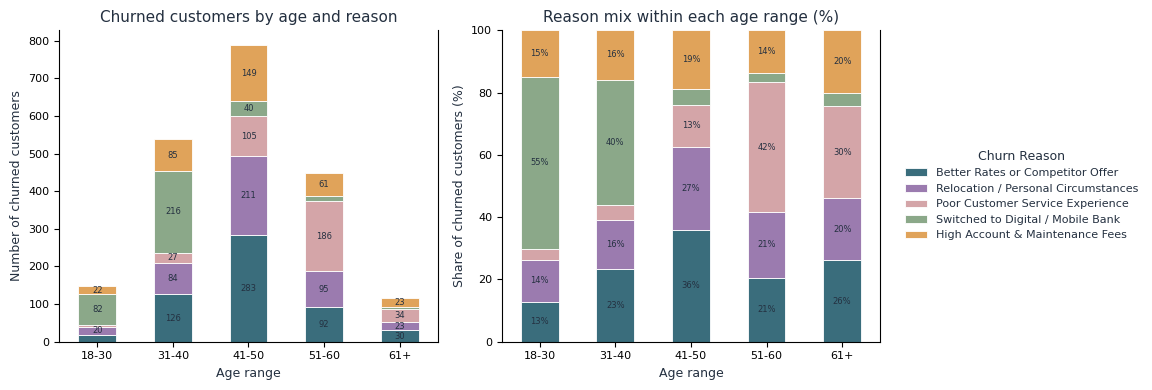

Churn_Reason  Better Rates or Competitor Offer  \
Age_Range                                        
18-30                                       19   
31-40                                      126   
41-50                                      283   
51-60                                       92   
61+                                         30   

Churn_Reason  Relocation / Personal Circumstances  \
Age_Range                                           
18-30                                          20   
31-40                                          84   
41-50                                         211   
51-60                                          95   
61+                                            23   

Churn_Reason  Poor Customer Service Experience  \
Age_Range                                        
18-30                                        5   
31-40                                       27   
41-50                                      105   
51-60                      

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Same age ranges as in the previous age chart
age_bins = [18, 31, 41, 51, 61, np.inf]
age_labels = ['18-30', '31-40', '41-50', '51-60', '61+']
db_bank_churn['Age_Range'] = pd.cut(
    db_bank_churn['Age'],
    bins=age_bins,
    labels=age_labels,
    right=False,
    include_lowest=True
)

churned = db_bank_churn.loc[db_bank_churn['Exited'] == 1]
counts = ordered_reasons(
    pd.crosstab(churned['Age_Range'], churned['Churn_Reason']).reindex(age_labels, fill_value=0)
)
pct = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
colors = reason_palette(counts.columns)

counts.plot(
    kind='bar', stacked=True, ax=axes[0], color=colors,
    edgecolor='white', linewidth=0.6, legend=False
)
axes[0].set_title('Churned customers by age and reason')
axes[0].set_xlabel('Age range')
axes[0].set_ylabel('Number of churned customers')
axes[0].tick_params(axis='x', rotation=0)

pct.plot(
    kind='bar', stacked=True, ax=axes[1], color=colors,
    edgecolor='white', linewidth=0.6, legend=False
)
axes[1].set_title('Reason mix within each age range (%)')
axes[1].set_xlabel('Age range')
axes[1].set_ylabel('Share of churned customers (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].set_ylim(0, 100)

for container in axes[0].containers:
    axes[0].bar_label(
        container, label_type='center', fontsize=6, color=INK,
        labels=[f'{v:.0f}' if v >= 20 else '' for v in container.datavalues]
    )
for container in axes[1].containers:
    axes[1].bar_label(
        container, label_type='center', fontsize=6, color=INK,
        labels=[f'{v:.0f}%' if v >= 8 else '' for v in container.datavalues]
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title='Churn Reason',
    loc='center left', bbox_to_anchor=(1.0, 0.5),
    fontsize=8, title_fontsize=9, frameon=False
)
plt.tight_layout()
plt.show()

print(counts)
print()
print(pct.round(1))


### 8.4 Reasons by country

Repeat the reason split for France, Germany, and Spain. We are looking for country patterns, such as competitor offers being much stronger in one market than in the others.


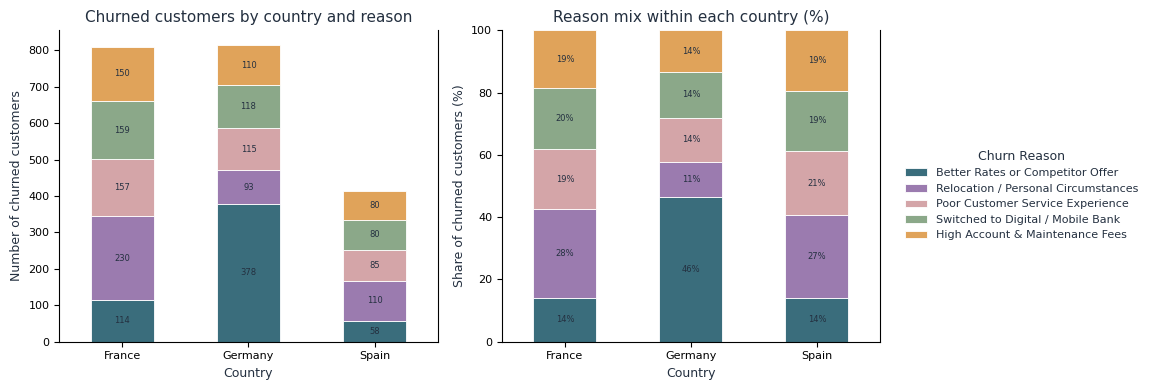

Churn_Reason  Better Rates or Competitor Offer  \
Geography                                        
France                                     114   
Germany                                    378   
Spain                                       58   

Churn_Reason  Relocation / Personal Circumstances  \
Geography                                           
France                                        230   
Germany                                        93   
Spain                                         110   

Churn_Reason  Poor Customer Service Experience  \
Geography                                        
France                                     157   
Germany                                    115   
Spain                                       85   

Churn_Reason  Switched to Digital / Mobile Bank  \
Geography                                         
France                                      159   
Germany                                     118   
Spain                       

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

churned = db_bank_churn.loc[db_bank_churn['Exited'] == 1]
counts = ordered_reasons(pd.crosstab(churned['Geography'], churned['Churn_Reason']))
pct = counts.div(counts.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
colors = reason_palette(counts.columns)

counts.plot(
    kind='bar', stacked=True, ax=axes[0], color=colors,
    edgecolor='white', linewidth=0.6, legend=False
)
axes[0].set_title('Churned customers by country and reason')
axes[0].set_xlabel('Country')
axes[0].set_ylabel('Number of churned customers')
axes[0].tick_params(axis='x', rotation=0)

pct.plot(
    kind='bar', stacked=True, ax=axes[1], color=colors,
    edgecolor='white', linewidth=0.6, legend=False
)
axes[1].set_title('Reason mix within each country (%)')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Share of churned customers (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].set_ylim(0, 100)

for container in axes[0].containers:
    axes[0].bar_label(
        container, label_type='center', fontsize=6, color=INK,
        labels=[f'{v:.0f}' if v >= 20 else '' for v in container.datavalues]
    )
for container in axes[1].containers:
    axes[1].bar_label(
        container, label_type='center', fontsize=6, color=INK,
        labels=[f'{v:.0f}%' if v >= 8 else '' for v in container.datavalues]
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title='Churn Reason',
    loc='center left', bbox_to_anchor=(1.0, 0.5),
    fontsize=8, title_fontsize=9, frameon=False
)
plt.tight_layout()
plt.show()

print(counts)
print()
print(pct.round(1))


### 8.5 Activity status and age

Compare active vs inactive members, with age as the extra split because it changes both the churn rate and the reason mix more than country or products. We are looking for inactive older customers as a high-risk pocket, and for whether their reasons differ from active customers of the same age.


C:\Users\USER\AppData\Local\Temp\ipykernel_13236\3935717988.py:77: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


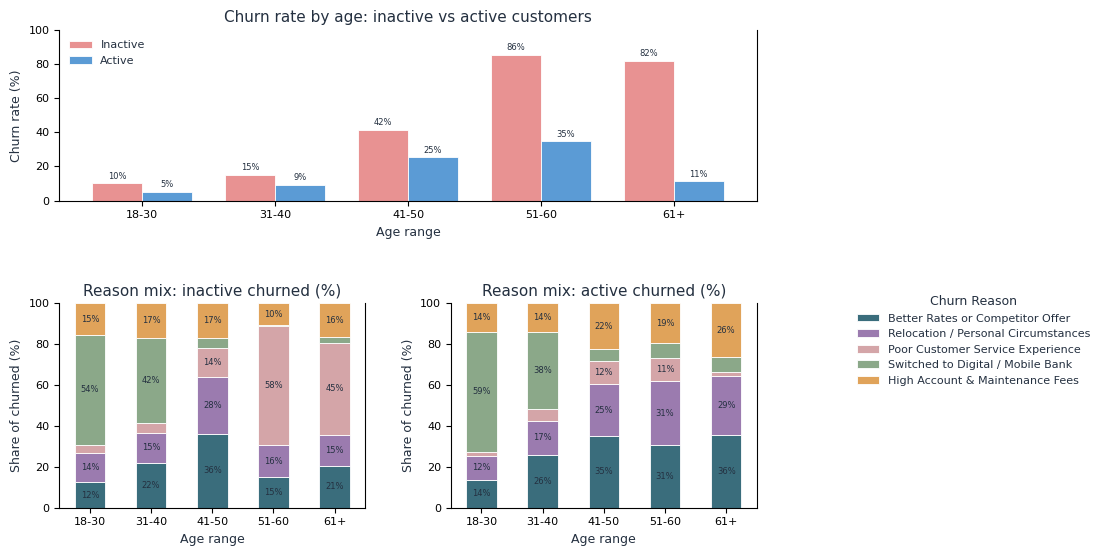

Overall churn rate for inactive customers: 26.85%
Overall churn rate for active customers: 14.27%


In [24]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Same age ranges as in previous charts. Age is used instead of country/products
# because the reason mix changes sharply with age, and inactive churn jumps at ages 51+.
age_bins = [18, 31, 41, 51, 61, np.inf]
age_labels = ['18-30', '31-40', '41-50', '51-60', '61+']
plot_df = db_bank_churn.copy()
plot_df['Age_Range'] = pd.cut(
    plot_df['Age'], bins=age_bins, labels=age_labels, right=False, include_lowest=True
)
plot_df['Activity'] = plot_df['IsActiveMember'].map({1: 'Active', 0: 'Inactive'})

churn_rate = (
    plot_df.groupby(['Age_Range', 'Activity'], observed=False)['Exited']
    .mean()
    .unstack()
    .reindex(index=age_labels, columns=['Inactive', 'Active']) * 100
)

churned = plot_df.loc[plot_df['Exited'] == 1]

def reason_mix_by_age(activity):
    sub = churned.loc[churned['Activity'] == activity]
    ct = ordered_reasons(pd.crosstab(sub['Age_Range'], sub['Churn_Reason']).reindex(age_labels, fill_value=0))
    return ct.div(ct.sum(axis=1).replace(0, np.nan), axis=0) * 100

inactive_pct = reason_mix_by_age('Inactive')
active_pct = reason_mix_by_age('Active')
colors = reason_palette(inactive_pct.columns)

fig = plt.figure(figsize=(9, 6.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2], hspace=0.55, wspace=0.28)
ax_rate = fig.add_subplot(gs[0, :])
ax_inact = fig.add_subplot(gs[1, 0])
ax_act = fig.add_subplot(gs[1, 1])

churn_rate.plot(
    kind='bar', ax=ax_rate, color=[CORAL, NAVY],
    edgecolor='white', linewidth=0.6, width=0.75
)
ax_rate.set_title('Churn rate by age: inactive vs active customers')
ax_rate.set_xlabel('Age range')
ax_rate.set_ylabel('Churn rate (%)')
ax_rate.tick_params(axis='x', rotation=0)
ax_rate.legend(fontsize=8, title=None, frameon=False)
ax_rate.set_ylim(0, 100)
for container in ax_rate.containers:
    ax_rate.bar_label(container, fmt='%.0f%%', fontsize=6, padding=2)

for ax, data, title in [
    (ax_inact, inactive_pct, 'Reason mix: inactive churned (%)'),
    (ax_act, active_pct, 'Reason mix: active churned (%)'),
]:
    data.plot(
        kind='bar', stacked=True, ax=ax, color=colors,
        edgecolor='white', linewidth=0.6, legend=False
    )
    ax.set_title(title)
    ax.set_xlabel('Age range')
    ax.set_ylabel('Share of churned (%)')
    ax.tick_params(axis='x', rotation=0)
    ax.set_ylim(0, 100)
    for container in ax.containers:
        ax.bar_label(
            container, label_type='center', fontsize=6, color=INK,
            labels=[f'{v:.0f}%' if v >= 8 else '' for v in container.datavalues]
        )

handles, labels = ax_inact.get_legend_handles_labels()
fig.legend(
    handles, labels, title='Churn Reason',
    loc='center left', bbox_to_anchor=(1.0, 0.38),
    fontsize=8, title_fontsize=9, frameon=False
)
plt.tight_layout()
plt.show()

overall_churn_rate = plot_df.groupby('Activity')['Exited'].mean() * 100
print(f"Overall churn rate for inactive customers: {overall_churn_rate['Inactive']:.2f}%")
print(f"Overall churn rate for active customers: {overall_churn_rate['Active']:.2f}%")


## 9. Retention priority

Use historical churn in each remaining-customer segment (age × products × activity × country) to flag high / medium / low risk. We are looking for a shortlist of groups still at the bank that combine enough customers, enough balance, and a high past churn rate — the people to protect first.


Churn Risk Overview
HIGH-RISK CUSTOMERS: 496  (6.2% of active customers)
BALANCE AT RISK: 51.37M
ESTIMATED ANNUAL REVENUE AT RISK: 2.05M  (4% of high-risk balances)
Low 82.0% | Medium 11.8% | High 6.2%
Medium + High risk: 18.0%  (1,433 of 7,963 active customers)


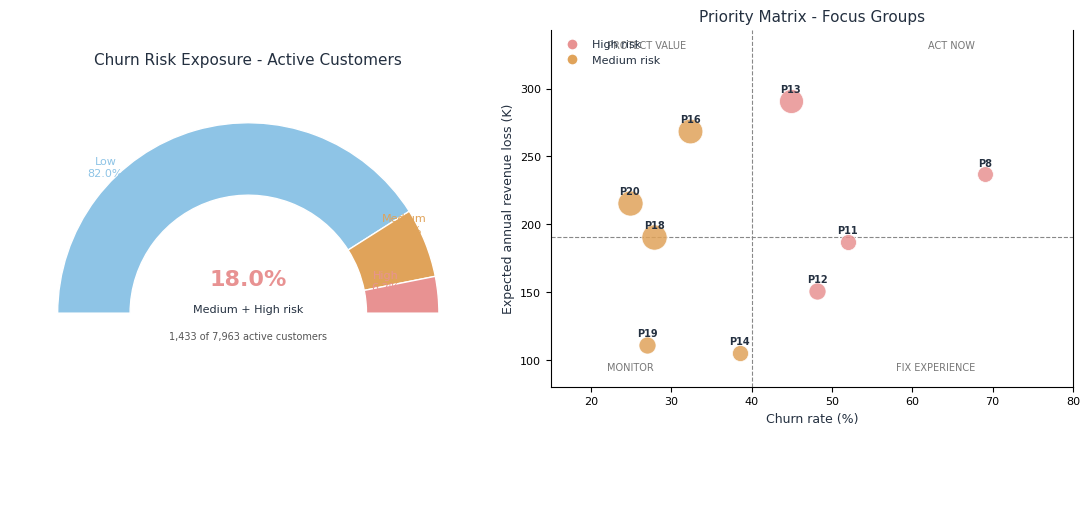

Rank,Group,Age,Products,Status,Country,Active Customers,Historical Churn,Est. Annual Rev. Loss
1,P13,41-50,1,Inactive,France,166,44.9%,291.0K
2,P16,31-40,1,Inactive,Germany,176,32.3%,269.0K
3,P8,41-50,1,Inactive,Germany,72,69.1%,236.8K
4,P20,31-40,1,Active,Germany,182,24.8%,215.8K
5,P18,41-50,1,Active,France,184,27.8%,190.8K
6,P11,41-50,1,Active,Germany,74,51.9%,187.3K
7,P12,41-50,1,Inactive,Spain,84,48.1%,150.9K
8,P19,18-30,1,Inactive,Germany,84,27.0%,111.1K
9,P14,51-60,1,Active,France,75,38.5%,105.6K



ADDITIONAL RISK INSIGHT: 3-product customers: 82.7% historical churn; only 46 remain. This segment requires further investigation.


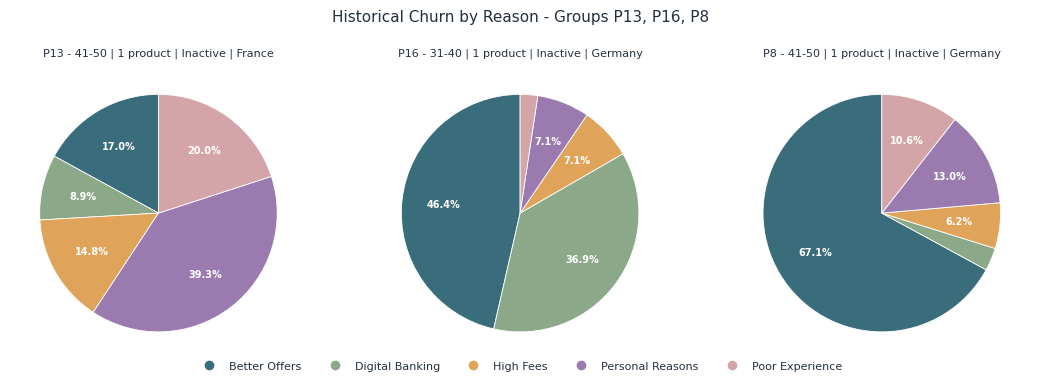

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Active customers = currently retained (Exited == 0), not IsActiveMember.
# Segment = Age range x products x activity x country.
# Historical churn = churned / all customers in that segment.
# High risk: segment n >= 12 and historical churn >= 40%.
# Medium: historical churn >= 20% (including tiny high-churn groups with n < 12).
# Est. annual revenue at risk = remaining balance * 4% * historical churn.

age_bins = [18, 31, 41, 51, 61, np.inf]
age_labels = ["18-30", "31-40", "41-50", "51-60", "61+"]
df = db_bank_churn.copy()
df["Age_Range"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels, right=False, include_lowest=True)
df["Activity"] = df["IsActiveMember"].map({1: "Active", 0: "Inactive"})
keys = ["Age_Range", "NumOfProducts", "Activity", "Geography"]

seg = (
    df.assign(
        is_retained=df["Exited"].eq(0),
        retained_balance=np.where(df["Exited"].eq(0), df["Balance"], 0.0),
    )
    .groupby(keys, observed=False)
    .agg(
        n=("Exited", "size"),
        churned=("Exited", "sum"),
        remaining=("is_retained", "sum"),
        rem_balance=("retained_balance", "sum"),
    )
    .reset_index()
)
seg["churn_rate"] = seg["churned"] / seg["n"].replace(0, np.nan)
seg["est_loss"] = 0.04 * seg["rem_balance"] * seg["churn_rate"]
seg["risk"] = np.select(
    [(seg["churn_rate"] >= 0.40) & (seg["n"] >= 12), seg["churn_rate"] >= 0.20],
    ["High", "Medium"],
    default="Low",
)

retained = df.loc[df["Exited"] == 0, keys + ["Balance"]].merge(
    seg[keys + ["churn_rate", "n", "risk"]], on=keys, how="left"
)
n_active = len(retained)
n_high = int((retained["risk"] == "High").sum())
n_med = int((retained["risk"] == "Medium").sum())
n_low = n_active - n_high - n_med
high_balance = retained.loc[retained["risk"] == "High", "Balance"].sum()
high_rev = high_balance * 0.04
pct_high = n_high / n_active * 100
pct_med = n_med / n_active * 100
pct_low = n_low / n_active * 100
pct_mh = pct_med + pct_high

print("Churn Risk Overview")
print(f"HIGH-RISK CUSTOMERS: {n_high:,}  ({pct_high:.1f}% of active customers)")
print(f"BALANCE AT RISK: {high_balance/1e6:.2f}M")
print(f"ESTIMATED ANNUAL REVENUE AT RISK: {high_rev/1e6:.2f}M  (4% of high-risk balances)")
print(f"Low {pct_low:.1f}% | Medium {pct_med:.1f}% | High {pct_high:.1f}%")
print(f"Medium + High risk: {pct_mh:.1f}%  ({n_med + n_high:,} of {n_active:,} active customers)")

pid_map = {
    ("41-50", 1, "Inactive", "France"): "P13",
    ("31-40", 1, "Inactive", "Germany"): "P16",
    ("41-50", 1, "Inactive", "Germany"): "P8",
    ("31-40", 1, "Active", "Germany"): "P20",
    ("41-50", 1, "Active", "France"): "P18",
    ("41-50", 1, "Active", "Germany"): "P11",
    ("41-50", 1, "Inactive", "Spain"): "P12",
    ("18-30", 1, "Inactive", "Germany"): "P19",
    ("51-60", 1, "Active", "France"): "P14",
}

focus = (
    seg[(seg["remaining"] >= 50) & (seg["rem_balance"] >= 5_000_000) & (seg["risk"].isin(["High", "Medium"]))]
    .copy()
    .sort_values("est_loss", ascending=False)
    .head(9)
)
focus["Group"] = [
    pid_map[(r.Age_Range, r.NumOfProducts, r.Activity, r.Geography)]
    for r in focus.itertuples(index=False)
]
focus["profile"] = focus.apply(
    lambda r: f"{r.Age_Range} | {int(r.NumOfProducts)} product | {r.Activity} | {r.Geography}",
    axis=1,
)
median_loss = focus["est_loss"].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.05, 1.15]})
ax_g, ax_s = axes

gauge_vals = [pct_low, pct_med, pct_high, 100]
gauge_colors = [TEAL, GOLD, CORAL, "white"]
wedges, _ = ax_g.pie(
    gauge_vals,
    colors=gauge_colors,
    startangle=180,
    counterclock=False,
    wedgeprops={"width": 0.38, "edgecolor": "white", "linewidth": 1},
)
ax_g.set_xlim(-1.25, 1.25)
ax_g.set_ylim(-0.15, 1.25)
ax_g.set_title("Churn Risk Exposure - Active Customers", fontsize=11, pad=8)
ax_g.text(0, 0.18, f"{pct_mh:.1f}%", ha="center", va="center", fontsize=16, fontweight="bold", color=CORAL)
ax_g.text(0, 0.02, "Medium + High risk", ha="center", va="center", fontsize=8)
ax_g.text(0, -0.12, f"{n_med + n_high:,} of {n_active:,} active customers", ha="center", va="center", fontsize=7, color="#555555")
ax_g.annotate(f"Low\n{pct_low:.1f}%", xy=(-0.75, 0.72), ha="center", fontsize=8, color=TEAL)
ax_g.annotate(f"Medium\n{pct_med:.1f}%", xy=(0.82, 0.42), ha="center", fontsize=8, color=GOLD)
ax_g.annotate(f"High\n{pct_high:.1f}%", xy=(0.72, 0.12), ha="center", fontsize=8, color=CORAL)

for _, r in focus.iterrows():
    color = CORAL if r["risk"] == "High" else GOLD
    ax_s.scatter(
        r["churn_rate"] * 100,
        r["est_loss"] / 1000,
        s=max(r["remaining"] * 1.8, 40),
        color=color,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.6,
        zorder=3,
    )
    ax_s.annotate(r["Group"], (r["churn_rate"] * 100, r["est_loss"] / 1000),
                  textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7, fontweight="bold")

ax_s.axvline(40, color="#888888", linestyle="--", linewidth=0.8)
ax_s.axhline(median_loss / 1000, color="#888888", linestyle="--", linewidth=0.8)
ax_s.set_xlabel("Churn rate (%)", fontsize=9)
ax_s.set_ylabel("Expected annual revenue loss (K)", fontsize=9)
ax_s.set_title("Priority Matrix - Focus Groups", fontsize=11)
ax_s.tick_params(labelsize=8)
ax_s.set_xlim(15, 80)
ymax = focus["est_loss"].max() / 1000 * 1.18
ax_s.set_ylim(80, ymax)
ax_s.text(22, ymax * 0.96, "PROTECT VALUE", fontsize=7, color="#777777")
ax_s.text(62, ymax * 0.96, "ACT NOW", fontsize=7, color="#777777")
ax_s.text(22, 92, "MONITOR", fontsize=7, color="#777777")
ax_s.text(58, 92, "FIX EXPERIENCE", fontsize=7, color="#777777")
ax_s.legend(
    handles=[
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=CORAL, markersize=8, label="High risk"),
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=GOLD, markersize=8, label="Medium risk"),
    ],
    fontsize=8,
    loc="upper left",
    frameon=False,
)
fig.tight_layout()
plt.show()

from IPython.display import display

table = focus.copy()
table["Rank"] = range(1, len(table) + 1)
table["Products"] = table["NumOfProducts"].astype(int)
table["Active Customers"] = table["remaining"].astype(int)
table["Historical Churn"] = (table["churn_rate"] * 100).map(lambda x: f"{x:.1f}%")
table["Est. Annual Rev. Loss"] = (table["est_loss"] / 1000).map(lambda x: f"{x:,.1f}K")
show = table.rename(columns={"Age_Range": "Age", "Activity": "Status", "Geography": "Country"})[
    ["Rank", "Group", "Age", "Products", "Status", "Country", "Active Customers", "Historical Churn", "Est. Annual Rev. Loss"]
]

display(
    show.style.hide(axis="index")
    .set_caption("Retention Priority Groups")
    .set_properties(**{
        "text-align": "left",
        "padding": "6px 10px",
        "font-size": "13px",
        "background-color": "white",
        "color": "black",
        "border": "1px solid #cccccc",
    })
    .set_table_styles([
        {"selector": "caption", "props": [("caption-side", "top"), ("font-weight", "bold"), ("font-size", "15px"), ("text-align", "left"), ("color", "black"), ("padding", "0 0 8px 0")]},
        {"selector": "th", "props": [("text-align", "left"), ("background-color", "#e6e6e6"), ("color", "black"), ("padding", "6px 10px"), ("font-weight", "bold"), ("border", "1px solid #cccccc")]},
        {"selector": "table", "props": [("border-collapse", "collapse"), ("background-color", "white")]},
    ])
)

prod3 = df[df["NumOfProducts"] == 3]
print(
    f"\nADDITIONAL RISK INSIGHT: 3-product customers: {prod3['Exited'].mean()*100:.1f}% historical churn; "
    f"only {(prod3['Exited']==0).sum()} remain. This segment requires further investigation."
)

reason_map = {
    "Better Rates or Competitor Offer": "Better Offers",
    "Switched to Digital / Mobile Bank": "Digital Banking",
    "High Account & Maintenance Fees": "High Fees",
    "Relocation / Personal Circumstances": "Personal Reasons",
    "Poor Customer Service Experience": "Poor Experience",
}
reason_colors = {
    "Better Offers": REASON_COLORS["Better Rates or Competitor Offer"],
    "Digital Banking": REASON_COLORS["Switched to Digital / Mobile Bank"],
    "High Fees": REASON_COLORS["High Account & Maintenance Fees"],
    "Personal Reasons": REASON_COLORS["Relocation / Personal Circumstances"],
    "Poor Experience": REASON_COLORS["Poor Customer Service Experience"],
}
pie_groups = ["P13", "P16", "P8"]
fig, pie_axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, gid in zip(pie_axes, pie_groups):
    r = focus.loc[focus["Group"] == gid].iloc[0]
    hist = df[
        (df["Exited"] == 1)
        & (df["Age_Range"] == r["Age_Range"])
        & (df["NumOfProducts"] == r["NumOfProducts"])
        & (df["Activity"] == r["Activity"])
        & (df["Geography"] == r["Geography"])
    ]
    counts = hist["Churn_Reason"].map(reason_map).value_counts()
    counts = counts.reindex([c for c in reason_colors if c in counts.index])
    ax.pie(
        counts,
        colors=[reason_colors[i] for i in counts.index],
        autopct=lambda p: f"{p:.1f}%" if p >= 4 else "",
        startangle=90,
        pctdistance=0.65,
        wedgeprops={"edgecolor": "white", "linewidth": 0.6},
        textprops={"fontsize": 7, "color": "white", "fontweight": "bold"},
    )
    ax.set_title(f"{gid} - {r['profile']}", fontsize=8)

handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=8, label=k) for k, c in reason_colors.items()]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=8, frameon=False)
fig.suptitle("Historical Churn by Reason - Groups P13, P16, P8", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()
